In [ ]:
# PCA - Use PCA algorithm for dimensionality reduction on wine dataset and visualize the data.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [ ]:
# 1. Load the Dataset

wine = load_wine()
X = wine.data
y = wine.target

In [ ]:
# 2. Convert into DataFrame
df = pd.DataFrame(X, columns=wine.feature_names)

# Add target column
df['target'] = y

In [ ]:
# 3. Basic Data Exploration

print("First 5 Rows:")
print(df.head())

First 5 Rows:
   alcohol  malic_acid   ash  alcalinity_of_ash  magnesium  total_phenols  \
0    14.23        1.71  2.43               15.6      127.0           2.80   
1    13.20        1.78  2.14               11.2      100.0           2.65   
2    13.16        2.36  2.67               18.6      101.0           2.80   
3    14.37        1.95  2.50               16.8      113.0           3.85   
4    13.24        2.59  2.87               21.0      118.0           2.80   

   flavanoids  nonflavanoid_phenols  proanthocyanins  color_intensity   hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   od280/od315_of_diluted_wines  proline  target

In [ ]:
print("Dataset Shape:")
print(df.shape)

Dataset Shape:
(178, 14)


In [ ]:
print("Dataset Information:")
print(df.info())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 14 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   alcohol                       178 non-null    float64
 1   malic_acid                    178 non-null    float64
 2   ash                           178 non-null    float64
 3   alcalinity_of_ash             178 non-null    float64
 4   magnesium                     178 non-null    float64
 5   total_phenols                 178 non-null    float64
 6   flavanoids                    178 non-null    float64
 7   nonflavanoid_phenols          178 non-null    float64
 8   proanthocyanins               178 non-null    float64
 9   color_intensity               178 non-null    float64
 10  hue                           178 non-null    float64
 11  od280/od315_of_diluted_wines  178 non-null    float64
 12  proline                       178 non-null 

In [ ]:
print("Statistical Description:")
print(df.describe())

Statistical Description:
          alcohol  malic_acid         ash  alcalinity_of_ash   magnesium  \
count  178.000000  178.000000  178.000000         178.000000  178.000000   
mean    13.000618    2.336348    2.366517          19.494944   99.741573   
std      0.811827    1.117146    0.274344           3.339564   14.282484   
min     11.030000    0.740000    1.360000          10.600000   70.000000   
25%     12.362500    1.602500    2.210000          17.200000   88.000000   
50%     13.050000    1.865000    2.360000          19.500000   98.000000   
75%     13.677500    3.082500    2.557500          21.500000  107.000000   
max     14.830000    5.800000    3.230000          30.000000  162.000000   

       total_phenols  flavanoids  nonflavanoid_phenols  proanthocyanins  \
count     178.000000  178.000000            178.000000       178.000000   
mean        2.295112    2.029270              0.361854         1.590899   
std         0.625851    0.998859              0.124453         0.

In [ ]:
print("Column Names:")
print(df.columns)

Column Names:
Index(['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium',
       'total_phenols', 'flavanoids', 'nonflavanoid_phenols',
       'proanthocyanins', 'color_intensity', 'hue',
       'od280/od315_of_diluted_wines', 'proline', 'target'],
      dtype='object')


In [ ]:
print("Missing Values:")
print(df.isnull().sum())

Missing Values:
alcohol                         0
malic_acid                      0
ash                             0
alcalinity_of_ash               0
magnesium                       0
total_phenols                   0
flavanoids                      0
nonflavanoid_phenols            0
proanthocyanins                 0
color_intensity                 0
hue                             0
od280/od315_of_diluted_wines    0
proline                         0
target                          0
dtype: int64


In [ ]:
print("\nTotal Missing Values:")
print(df.isnull().sum().sum())


Total Missing Values:
0


In [ ]:
print("Duplicate Rows:")
print(df.duplicated().sum())

Duplicate Rows:
0


In [ ]:
print("Wine Class Distribution:")
print(df['target'].value_counts())

Wine Class Distribution:
target
1    71
0    59
2    48
Name: count, dtype: int64


In [ ]:
# 4. Separate Features and Target

X = df.drop('target', axis=1)
y = df['target']

In [ ]:
print("Original Shape:", X.shape)

Original Shape: (178, 13)


In [ ]:
# 5. Feature Scaling

scaler = StandardScaler()
X = scaler.fit_transform(X)

In [ ]:
# 6. Apply PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X)

print("New Shape:", X_pca.shape)

New Shape: (178, 2)


In [ ]:
# 7. Explained Variance
print("Explained Variance Ratio:")
print(pca.explained_variance_ratio_)

print("\nTotal Explained Variance:")
print(pca.explained_variance_ratio_.sum())

Explained Variance Ratio:
[0.36198848 0.1920749 ]

Total Explained Variance:
0.5540633835693526


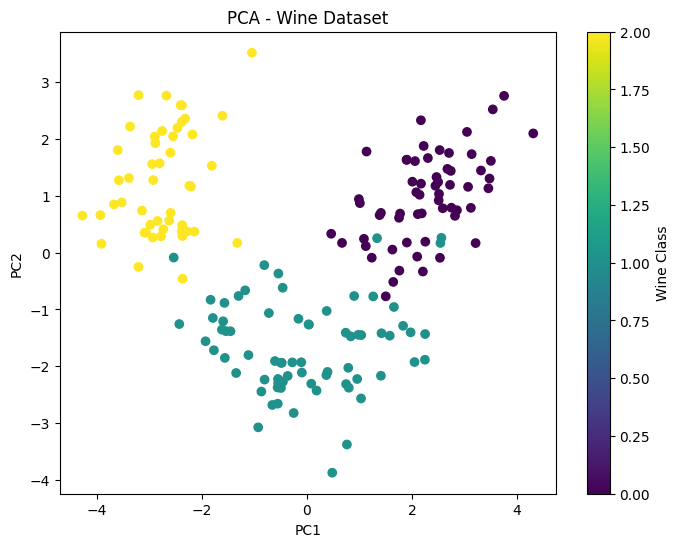

In [ ]:
# 8. Visualize PCA Results
plt.figure(figsize=(8, 6))

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=y, cmap='viridis')

plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title("PCA - Wine Dataset")

plt.colorbar(label="Wine Class")
plt.show()